In [1]:
!pip install -q -U kaggle
import os, getpass
os.environ["KAGGLE_API_TOKEN"] = getpass.getpass("Kaggle token: ")


[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: /Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [2]:
!kaggle datasets download -d emmarex/plantdisease -p /content

Dataset URL: https://www.kaggle.com/datasets/emmarex/plantdisease
License(s): unknown
100% 658M/658M [00:08<00:00, 76.8MB/s]



In [3]:
!mkdir -p /content/data
!unzip -q /content/*.zip -d /content/data

In [4]:
!ls /content/data
!ls /content/data/* | head -50

plantvillage  PlantVillage
/content/data/plantvillage:
PlantVillage

/content/data/PlantVillage:
Pepper__bell___Bacterial_spot
Pepper__bell___healthy
Potato___Early_blight
Potato___healthy
Potato___Late_blight
Tomato_Bacterial_spot
Tomato_Early_blight
Tomato_healthy
Tomato_Late_blight
Tomato_Leaf_Mold
Tomato_Septoria_leaf_spot
Tomato_Spider_mites_Two_spotted_spider_mite
Tomato__Target_Spot
Tomato__Tomato_mosaic_virus
Tomato__Tomato_YellowLeaf__Curl_Virus


In [5]:
import os, shutil

DATA_DIR = "/content/data/PlantVillage"   # change to the folder that directly contains the class folders
DEST = "/content/tomato"
os.makedirs(DEST, exist_ok=True)

for name in sorted(os.listdir(DATA_DIR)):
    if name.lower().startswith("tomato"):
        shutil.copytree(os.path.join(DATA_DIR, name), os.path.join(DEST, name), dirs_exist_ok=True)

for c in sorted(os.listdir(DEST)):
    print(c, len(os.listdir(os.path.join(DEST, c))))

Tomato_Bacterial_spot 2127
Tomato_Early_blight 1000
Tomato_Late_blight 1909
Tomato_Leaf_Mold 952
Tomato_Septoria_leaf_spot 1771
Tomato_Spider_mites_Two_spotted_spider_mite 1676
Tomato__Target_Spot 1404
Tomato__Tomato_YellowLeaf__Curl_Virus 3209
Tomato__Tomato_mosaic_virus 373
Tomato_healthy 1591


In [6]:
import shutil
from google.colab import drive
drive.mount('/content/drive')
shutil.make_archive("/content/drive/MyDrive/tomato_plantvillage", "zip", "/content/tomato")

Mounted at /content/drive


'/content/drive/MyDrive/tomato_plantvillage.zip'

In [7]:
!rm -rf /content/data /content/*.zip

In [8]:
import os, json
from sklearn.model_selection import train_test_split

DEST = "/content/tomato"
classes = sorted(os.listdir(DEST))
class_to_idx = {c: i for i, c in enumerate(classes)}

paths, labels = [], []
for c in classes:
    for f in os.listdir(os.path.join(DEST, c)):
        if f.lower().endswith((".jpg", ".jpeg", ".png")):
            paths.append(os.path.join(DEST, c, f))
            labels.append(class_to_idx[c])

train_p, temp_p, train_l, temp_l = train_test_split(
    paths, labels, test_size=0.30, stratify=labels, random_state=42)
val_p, test_p, val_l, test_l = train_test_split(
    temp_p, temp_l, test_size=0.50, stratify=temp_l, random_state=42)

print(len(train_p), len(val_p), len(test_p))

split = {"classes": classes,
         "train": list(zip(train_p, train_l)),
         "val": list(zip(val_p, val_l)),
         "test": list(zip(test_p, test_l))}
with open("/content/drive/MyDrive/split.json", "w") as f:
    json.dump(split, f)

11207 2402 2402


In [9]:
import json, torch, torch.nn as nn
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

with open("/content/drive/MyDrive/split.json") as f:
    split = json.load(f)
classes = split["classes"]

class LeafDS(Dataset):
    def __init__(self, items, tf):
        self.items, self.tf = items, tf
    def __len__(self):
        return len(self.items)
    def __getitem__(self, i):
        p, y = self.items[i]
        return self.tf(Image.open(p).convert("RGB")), y

train_tf = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
])
eval_tf = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
])

train_dl = DataLoader(LeafDS(split["train"], train_tf), batch_size=64, shuffle=True, num_workers=2)
val_dl   = DataLoader(LeafDS(split["val"],   eval_tf),  batch_size=64, num_workers=2)
test_dl  = DataLoader(LeafDS(split["test"],  eval_tf),  batch_size=64, num_workers=2)

cuda


In [10]:
def block(i, o):
    return nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(), nn.MaxPool2d(2))

class SmallCNN(nn.Module):
    def __init__(self, n_classes):
        super().__init__()
        self.features = nn.Sequential(block(3, 32), block(32, 64), block(64, 128))
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.3), nn.Linear(128, n_classes))
    def forward(self, x):
        return self.head(self.features(x))

model = SmallCNN(len(classes)).to(device)
loss_fn = nn.CrossEntropyLoss()
opt = torch.optim.Adam(model.parameters(), lr=1e-3)

In [11]:
def run_epoch(dl, train):
    model.train(train)
    total, correct, loss_sum = 0, 0, 0.0
    with torch.set_grad_enabled(train):
        for x, y in dl:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = loss_fn(out, y)
            if train:
                opt.zero_grad()
                loss.backward()
                opt.step()
            loss_sum += loss.item() * len(y)
            correct += (out.argmax(1) == y).sum().item()
            total += len(y)
    return loss_sum / total, correct / total

best_val = 0
for epoch in range(15):
    tr_loss, tr_acc = run_epoch(train_dl, True)
    va_loss, va_acc = run_epoch(val_dl, False)
    print(f"epoch {epoch+1}: train acc {tr_acc:.3f} loss {tr_loss:.3f} | val acc {va_acc:.3f} loss {va_loss:.3f}")
    if va_acc > best_val:
        best_val = va_acc
        torch.save(model.state_dict(), "/content/drive/MyDrive/cnn_baseline.pt")

epoch 1: train acc 0.646 loss 1.144 | val acc 0.746 loss 0.789
epoch 2: train acc 0.787 loss 0.688 | val acc 0.716 loss 0.750
epoch 3: train acc 0.816 loss 0.578 | val acc 0.640 loss 1.054
epoch 4: train acc 0.848 loss 0.480 | val acc 0.501 loss 1.571
epoch 5: train acc 0.863 loss 0.430 | val acc 0.748 loss 0.695
epoch 6: train acc 0.880 loss 0.386 | val acc 0.756 loss 0.670
epoch 7: train acc 0.881 loss 0.370 | val acc 0.727 loss 0.794
epoch 8: train acc 0.895 loss 0.336 | val acc 0.515 loss 2.181
epoch 9: train acc 0.901 loss 0.310 | val acc 0.811 loss 0.541
epoch 10: train acc 0.908 loss 0.288 | val acc 0.786 loss 0.566
epoch 11: train acc 0.909 loss 0.284 | val acc 0.209 loss 8.925
epoch 12: train acc 0.905 loss 0.286 | val acc 0.604 loss 1.405
epoch 13: train acc 0.912 loss 0.267 | val acc 0.779 loss 0.654
epoch 14: train acc 0.924 loss 0.243 | val acc 0.933 loss 0.231
epoch 15: train acc 0.922 loss 0.238 | val acc 0.854 loss 0.398


In [12]:
model.load_state_dict(torch.load("/content/drive/MyDrive/cnn_baseline.pt"))
print("test loss, acc:", run_epoch(test_dl, False))

test loss, acc: (0.22274220153552904, 0.9308909242298085)


In [13]:
from torchvision import models

# same size as the baseline, plus the normalization ResNet was pretrained with
norm = transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
r_train_tf = transforms.Compose([transforms.Resize((128, 128)), transforms.RandomHorizontalFlip(), transforms.ToTensor(), norm])
r_eval_tf  = transforms.Compose([transforms.Resize((128, 128)), transforms.ToTensor(), norm])

r_train_dl = DataLoader(LeafDS(split["train"], r_train_tf), batch_size=64, shuffle=True, num_workers=2)
r_val_dl   = DataLoader(LeafDS(split["val"],   r_eval_tf),  batch_size=64, num_workers=2)
r_test_dl  = DataLoader(LeafDS(split["test"],  r_eval_tf),  batch_size=64, num_workers=2)

model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
model.fc = nn.Linear(model.fc.in_features, len(classes))
model = model.to(device)
opt = torch.optim.Adam(model.parameters(), lr=1e-4)

best_val = 0
for epoch in range(5):
    tr_loss, tr_acc = run_epoch(r_train_dl, True)
    va_loss, va_acc = run_epoch(r_val_dl, False)
    print(f"epoch {epoch+1}: train acc {tr_acc:.3f} | val acc {va_acc:.3f} loss {va_loss:.3f}")
    if va_acc > best_val:
        best_val = va_acc
        torch.save(model.state_dict(), "/content/drive/MyDrive/resnet18.pt")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 186MB/s]


epoch 1: train acc 0.893 | val acc 0.972 loss 0.092
epoch 2: train acc 0.983 | val acc 0.983 loss 0.057
epoch 3: train acc 0.992 | val acc 0.985 loss 0.049
epoch 4: train acc 0.990 | val acc 0.984 loss 0.052
epoch 5: train acc 0.995 | val acc 0.985 loss 0.054


In [14]:
model.load_state_dict(torch.load("/content/drive/MyDrive/resnet18.pt"))
print("resnet test loss, acc:", run_epoch(r_test_dl, False))

resnet test loss, acc: (0.04956156641964511, 0.9829308909242298)


=== ResNet18 ===
                                      precision    recall  f1-score   support

                      Bacterial_spot      0.984     0.994     0.989       319
                        Early_blight      0.946     0.940     0.943       150
                         Late_blight      0.982     0.976     0.979       287
                           Leaf_Mold      0.966     0.993     0.979       143
                  Septoria_leaf_spot      0.992     0.977     0.985       265
Spider_mites_Two_spotted_spider_mite      0.988     0.972     0.980       252
                        _Target_Spot      0.949     0.976     0.962       210
             _YellowLeaf__Curl_Virus      0.998     0.994     0.996       482
                       _mosaic_virus      1.000     1.000     1.000        56
                             healthy      0.996     0.996     0.996       238

                            accuracy                          0.983      2402
                           macro avg      0.9

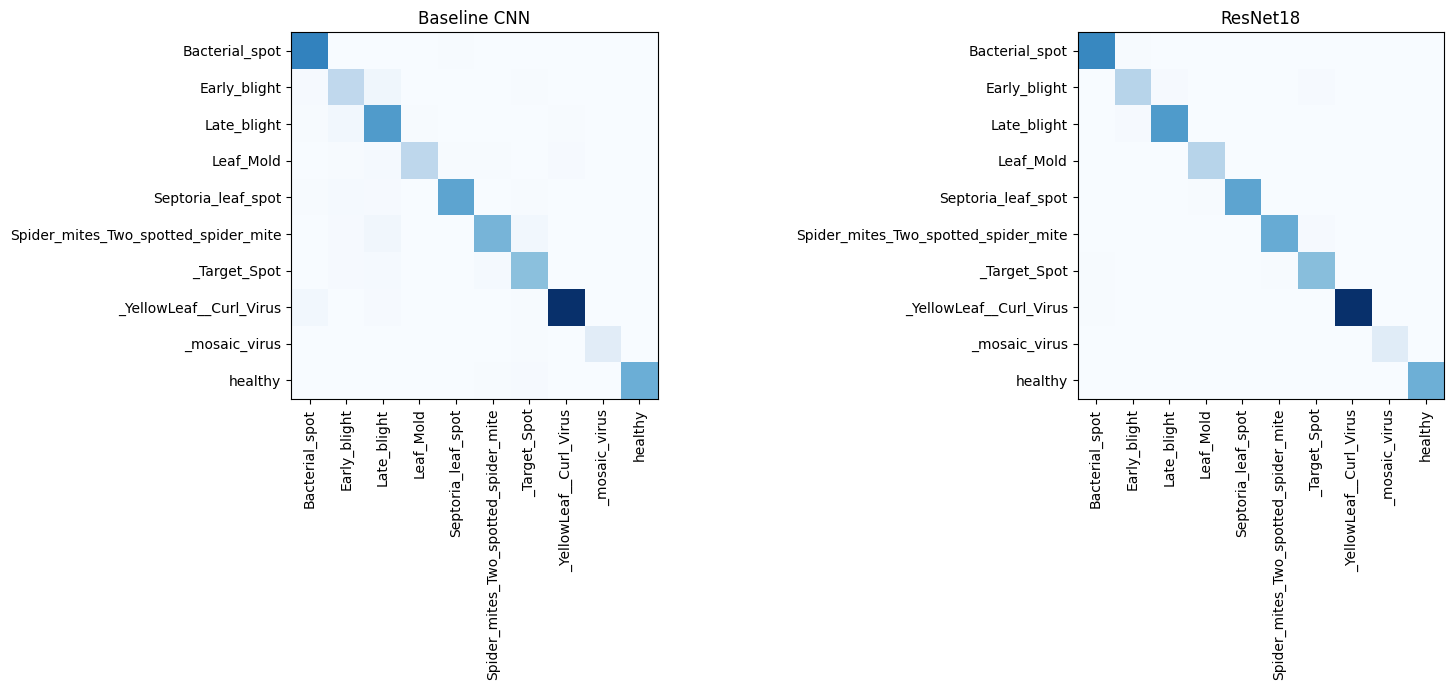

In [15]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt

def predict(m, dl):
    m.eval()
    ys, ps = [], []
    with torch.no_grad():
        for x, y in dl:
            ps += m(x.to(device)).argmax(1).cpu().tolist()
            ys += y.tolist()
    return np.array(ys), np.array(ps)

# ResNet (currently loaded in `model` from Cell 14)
resnet = model
y_r, p_r = predict(resnet, r_test_dl)

# Baseline CNN
cnn = SmallCNN(len(classes)).to(device)
cnn.load_state_dict(torch.load("/content/drive/MyDrive/cnn_baseline.pt"))
y_c, p_c = predict(cnn, test_dl)

short = [c.replace("Tomato_", "").replace("Tomato__", "") for c in classes]
print("=== ResNet18 ===")
print(classification_report(y_r, p_r, target_names=short, digits=3))
print("=== Baseline CNN ===")
print(classification_report(y_c, p_c, target_names=short, digits=3))

fig, ax = plt.subplots(1, 2, figsize=(16, 7))
for a, (y, p, t) in zip(ax, [(y_c, p_c, "Baseline CNN"), (y_r, p_r, "ResNet18")]):
    a.imshow(confusion_matrix(y, p), cmap="Blues")
    a.set_title(t)
    a.set_xticks(range(len(short))); a.set_xticklabels(short, rotation=90)
    a.set_yticks(range(len(short))); a.set_yticklabels(short)
plt.tight_layout()
plt.savefig("/content/drive/MyDrive/confusion.png", dpi=150)
plt.show()

In [16]:
cm = confusion_matrix(y_c, p_c)
pairs = [(cm[i, j], short[i], short[j]) for i in range(len(short)) for j in range(len(short)) if i != j and cm[i, j] > 0]
for n, true, pred in sorted(pairs, reverse=True)[:8]:
    print(f"{n:4d}  true {true}  ->  predicted {pred}")

  17  true Early_blight  ->  predicted Late_blight
  16  true Spider_mites_Two_spotted_spider_mite  ->  predicted Late_blight
  14  true Spider_mites_Two_spotted_spider_mite  ->  predicted _Target_Spot
  13  true _YellowLeaf__Curl_Virus  ->  predicted Bacterial_spot
  13  true Late_blight  ->  predicted Early_blight
   7  true Septoria_leaf_spot  ->  predicted Early_blight
   6  true _Target_Spot  ->  predicted Spider_mites_Two_spotted_spider_mite
   6  true _Target_Spot  ->  predicted Late_blight


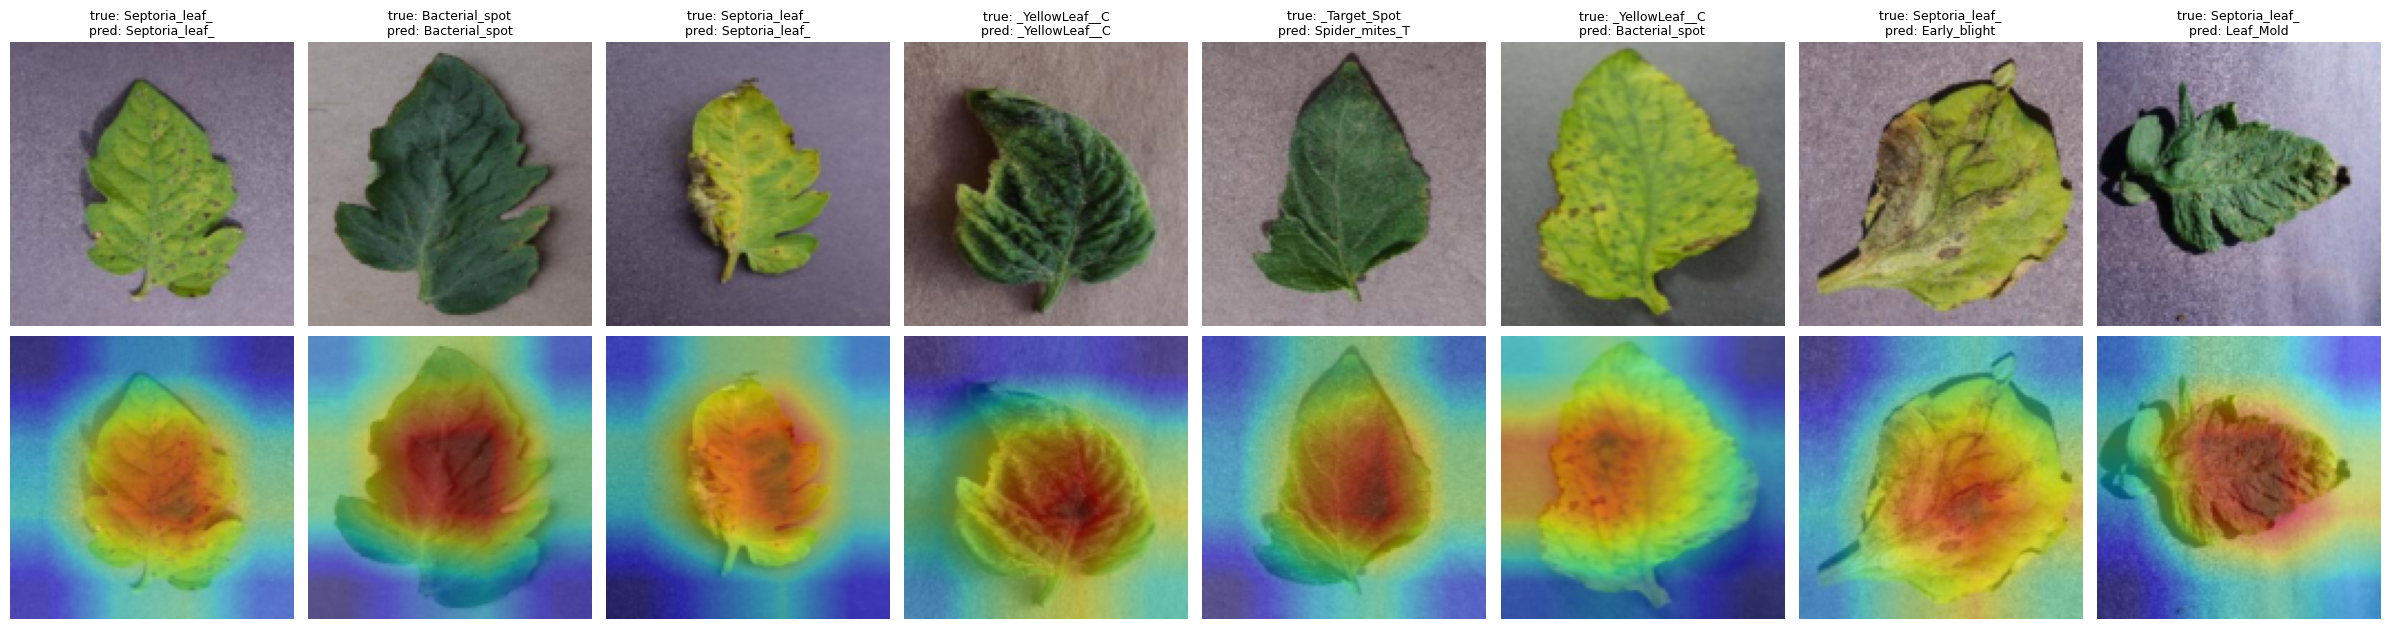

In [17]:
import torch.nn.functional as F

class GradCAM:
    def __init__(self, model, layer):
        self.model, self.acts, self.grads = model, None, None
        def fwd(m, i, o):
            self.acts = o
            if o.requires_grad: o.register_hook(lambda g: setattr(self, "grads", g))
        layer.register_forward_hook(fwd)
    def __call__(self, x, cls=None):
        self.model.eval()
        out = self.model(x)
        cls = out.argmax(1).item() if cls is None else cls
        self.model.zero_grad()
        out[0, cls].backward()
        w = self.grads.mean((2, 3), keepdim=True)
        cam = F.relu((w * self.acts).sum(1, keepdim=True))
        cam = F.interpolate(cam, size=x.shape[2:], mode="bilinear", align_corners=False)[0, 0]
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam.detach().cpu().numpy(), cls

cam_fn = GradCAM(resnet, resnet.layer4[-1])
mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

test_items = split["test"]
wrong = np.where(y_r != p_r)[0][:4].tolist()
right = np.random.RandomState(0).choice(np.where(y_r == p_r)[0], 4, replace=False).tolist()

fig, axes = plt.subplots(2, 8, figsize=(24, 6.5))
for k, idx in enumerate(right + wrong):
    x = r_eval_tf(Image.open(test_items[idx][0]).convert("RGB")).unsqueeze(0).to(device)
    cam, pred = cam_fn(x)
    img = (x[0].cpu() * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()
    axes[0, k].imshow(img); axes[0, k].axis("off")
    axes[0, k].set_title(f"true: {short[y_r[idx]][:14]}\npred: {short[pred][:14]}", fontsize=9)
    axes[1, k].imshow(img); axes[1, k].imshow(cam, cmap="jet", alpha=0.45); axes[1, k].axis("off")
plt.tight_layout()
plt.savefig("/content/drive/MyDrive/gradcam.png", dpi=150)
plt.show()

In [18]:
from PIL import ImageFilter, ImageEnhance

rng = np.random.default_rng(0)

def p_none(img):   return img
def p_blur(img):   return img.filter(ImageFilter.GaussianBlur(2))
def p_dark(img):   return ImageEnhance.Brightness(img).enhance(0.5)
def p_bright(img): return ImageEnhance.Brightness(img).enhance(1.5)
def p_noise(img):
    a = np.array(img).astype(np.float32) + rng.normal(0, 25, (img.size[1], img.size[0], 3))
    return Image.fromarray(a.clip(0, 255).astype(np.uint8))
def p_center(img):
    w, h = img.size
    m = Image.new("RGB", (w, h), (124, 116, 104))
    box = (int(w * .2), int(h * .2), int(w * .8), int(h * .8))
    m.paste(img.crop(box), box)
    return m

class PertDS(Dataset):
    def __init__(self, items, tf, pert):
        self.items, self.tf, self.pert = items, tf, pert
    def __len__(self):
        return len(self.items)
    def __getitem__(self, i):
        p, y = self.items[i]
        return self.tf(self.pert(Image.open(p).convert("RGB"))), y

def acc(m, tf, pert):
    dl = DataLoader(PertDS(split["test"], tf, pert), batch_size=64, num_workers=2)
    y, p = predict(m, dl)
    return (y == p).mean()

perts = {"original": p_none, "blur": p_blur, "darker": p_dark,
         "brighter": p_bright, "noise": p_noise, "center only": p_center}

print(f"{'test':12s} {'baseline':>9s} {'resnet18':>9s}")
for name, f in perts.items():
    print(f"{name:12s} {acc(cnn, eval_tf, f):9.3f} {acc(resnet, r_eval_tf, f):9.3f}")

test          baseline  resnet18
original         0.931     0.983
blur             0.577     0.620
darker           0.216     0.902
brighter         0.428     0.843
noise            0.289     0.657
center only      0.316     0.617
